# 03 · Phase 2 — Deep learning on the road graph (ST-GAT, hybrid, ablations)

Phase 1 found that one-hop neighbour features help XGBoost by 4.1% at 15 min but only 1.8% at 60 min.
Phase 2 asks whether a network that **learns** to pass information several hops along the road graph closes that gap.
Everything that defined the Phase 1 comparison is unchanged: masking, chronological split with gaps, the
one-hour window, horizons, test samples and the evaluation code. Training runs in `scripts/train_dl.py`
(~40 min per main model on 2 CPU cores); this notebook loads the saved predictions and shows the evidence.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from trafficml import config as C, data, features as F, models as M, evaluate as E
pd.set_option("display.width", 140); pd.set_option("display.precision", 3)
def fig(name, width=820):
    display(Image(filename=str(C.FIGURES_DIR / f"{name}.png"), width=width))
print("project root:", ROOT)
import torch
from trafficml.dl.data import build_graph_data, batch_iter
from trafficml.dl.models import STNet
from trafficml.dl.train import RunConfig, build_model
DL = C.RESULTS_DIR / 'dl'

project root: /home/claude/traffic-flow-phase1


## 1. Data as graph sequences
Each example is the last hour of every sensor (12 × 207 × 7 features) → the speed 15/30/60 min later. Outages: z-scored value 0 plus a mask channel, never 0 mph.

In [2]:
gd = build_graph_data()
print("x_all", gd.x_all.shape, "  y_all", gd.y_all.shape)
print("train / val / test samples:", len(gd.split.train), len(gd.split.val), len(gd.split.test))
print("features: speed_z, mask, tod_sin, tod_cos, dow_sin, dow_cos, usual_speed_z")
print("share of inputs that are outages:", round(1 - gd.x_all[:, :, 1].mean(), 4))

x_all (34272, 207, 7)   y_all (34272, 207, 3)
train / val / test samples: 23967 3403 6831
features: speed_z, mask, tod_sin, tod_cos, dow_sin, dow_cos, usual_speed_z
share of inputs that are outages: 0.0811


## 2. The model
One skeleton; only the spatial block changes (`none` = no graph, `gcn` = fixed diffusion, `gat` = attention).

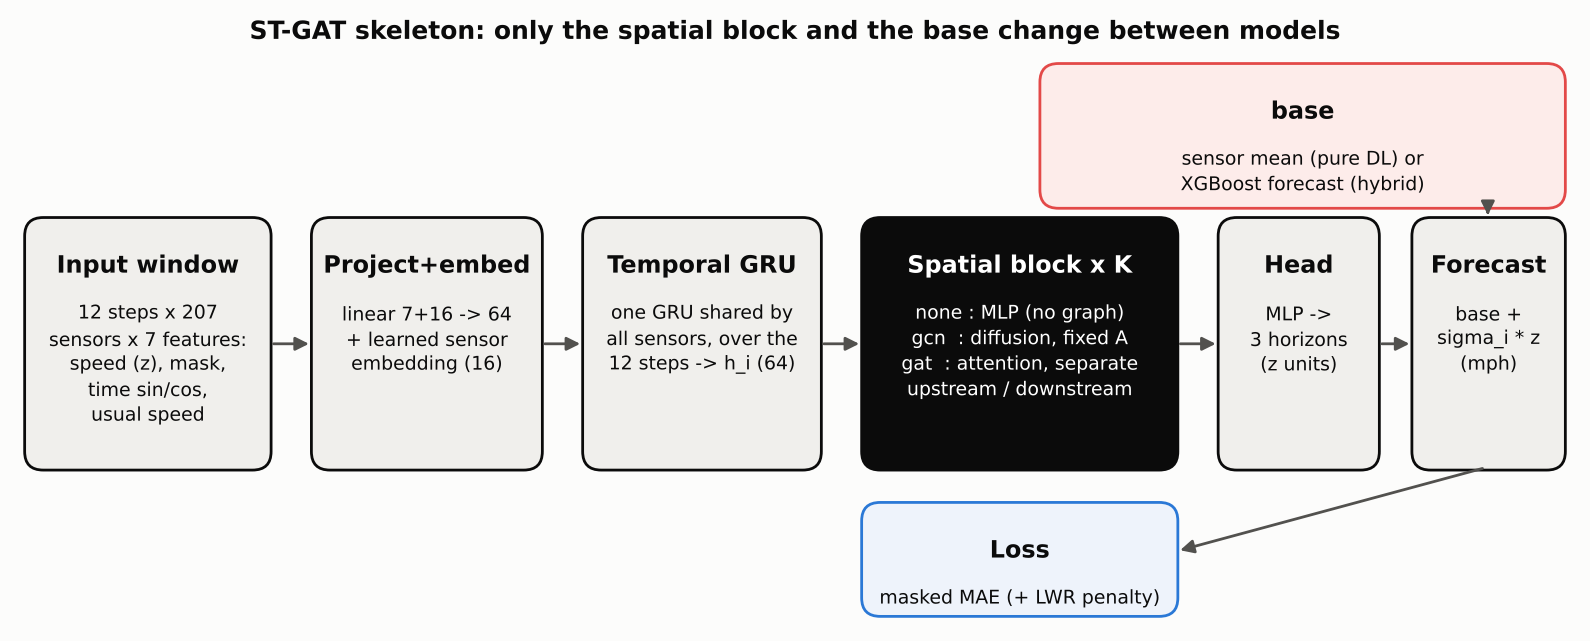

none  43763 parameters
gcn   60403 parameters
gat   43899 parameters


In [3]:
fig("fig_dl_architecture", 900)
for sp in ("none", "gcn", "gat"):
    m = build_model(RunConfig(spatial=sp), gd)
    print(f"{sp:5s}", sum(p.numel() for p in m.parameters()), "parameters")

## 3. Training curves (early stopping on validation masked MAE)

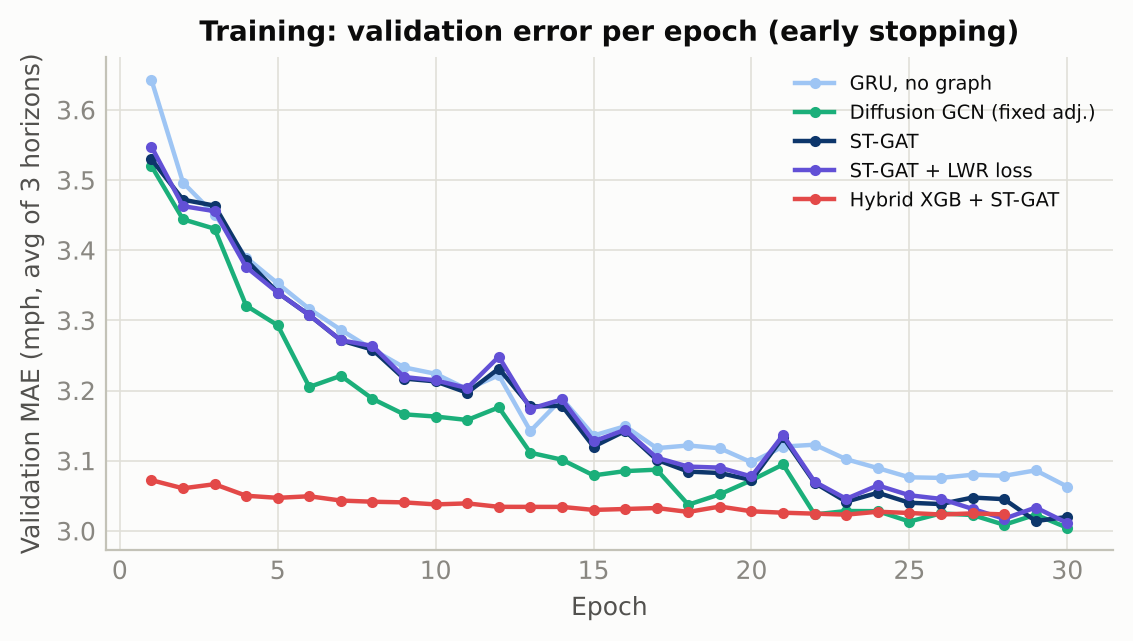

In [4]:
fig("fig_dl_training_curves", 650)

## 4. Results on the June test weeks (same samples as Phase 1)

In [5]:
hor = pd.read_csv(DL / "metrics_horizon.csv")
main = ["HA", "Persistence", "XGB-spatial", "RF-spatial", "GRU-nograph", "DCRNN-lite", "ST-GAT", "ST-GAT-LWR", "Hybrid-XGB-GAT"]
hor[hor.model.isin(main)].pivot(index="model", columns="horizon", values="MAE").loc[[m for m in main if m in set(hor.model)]].round(3)

horizon,15min,30min,60min,average
model,,,,
HA,4.193,4.193,4.194,4.193
Persistence,3.485,4.180,5.333,4.333
XGB-spatial,2.867,3.323,3.783,3.324
RF-spatial,2.872,3.309,3.810,3.331
GRU-nograph,2.913,3.306,3.714,3.311
DCRNN-lite,2.881,3.238,3.657,3.259
ST-GAT,2.875,3.256,3.677,3.269
ST-GAT-LWR,2.875,3.252,3.678,3.269
Hybrid-XGB-GAT,2.798,3.225,3.676,3.233


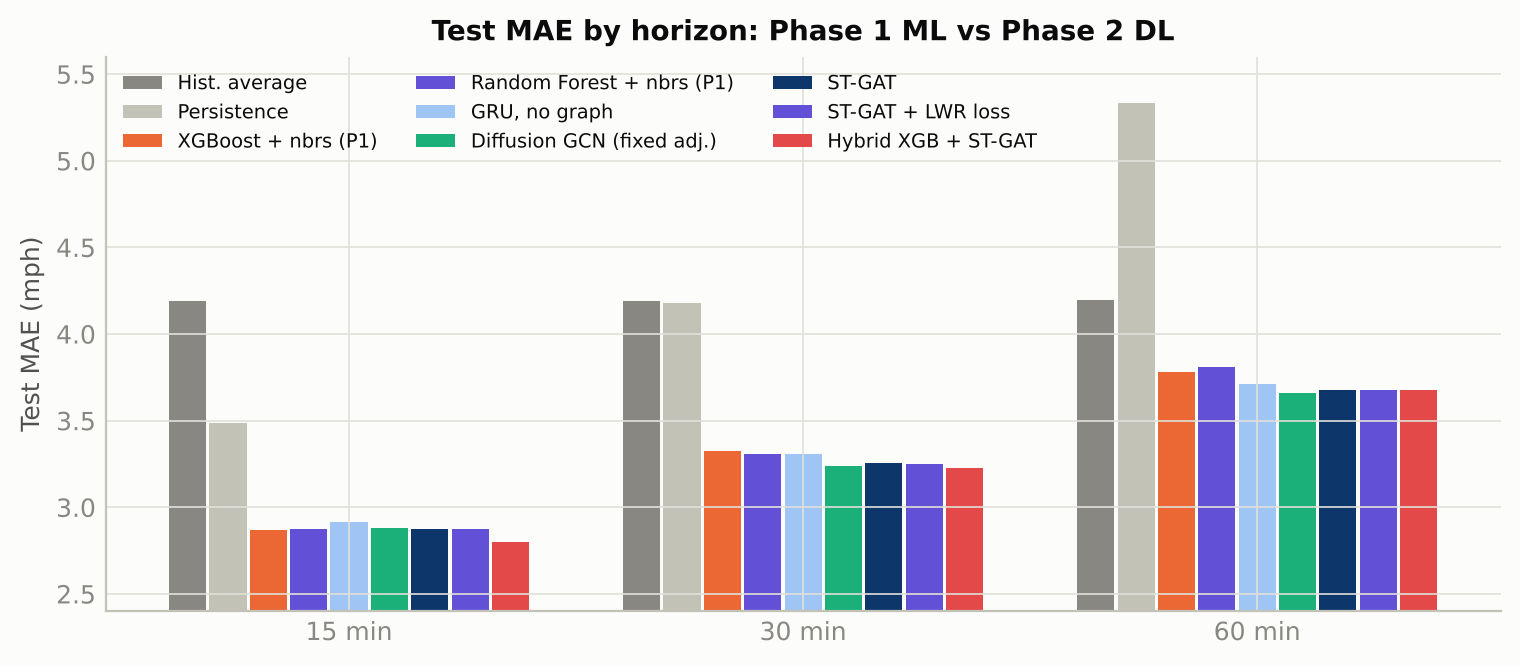

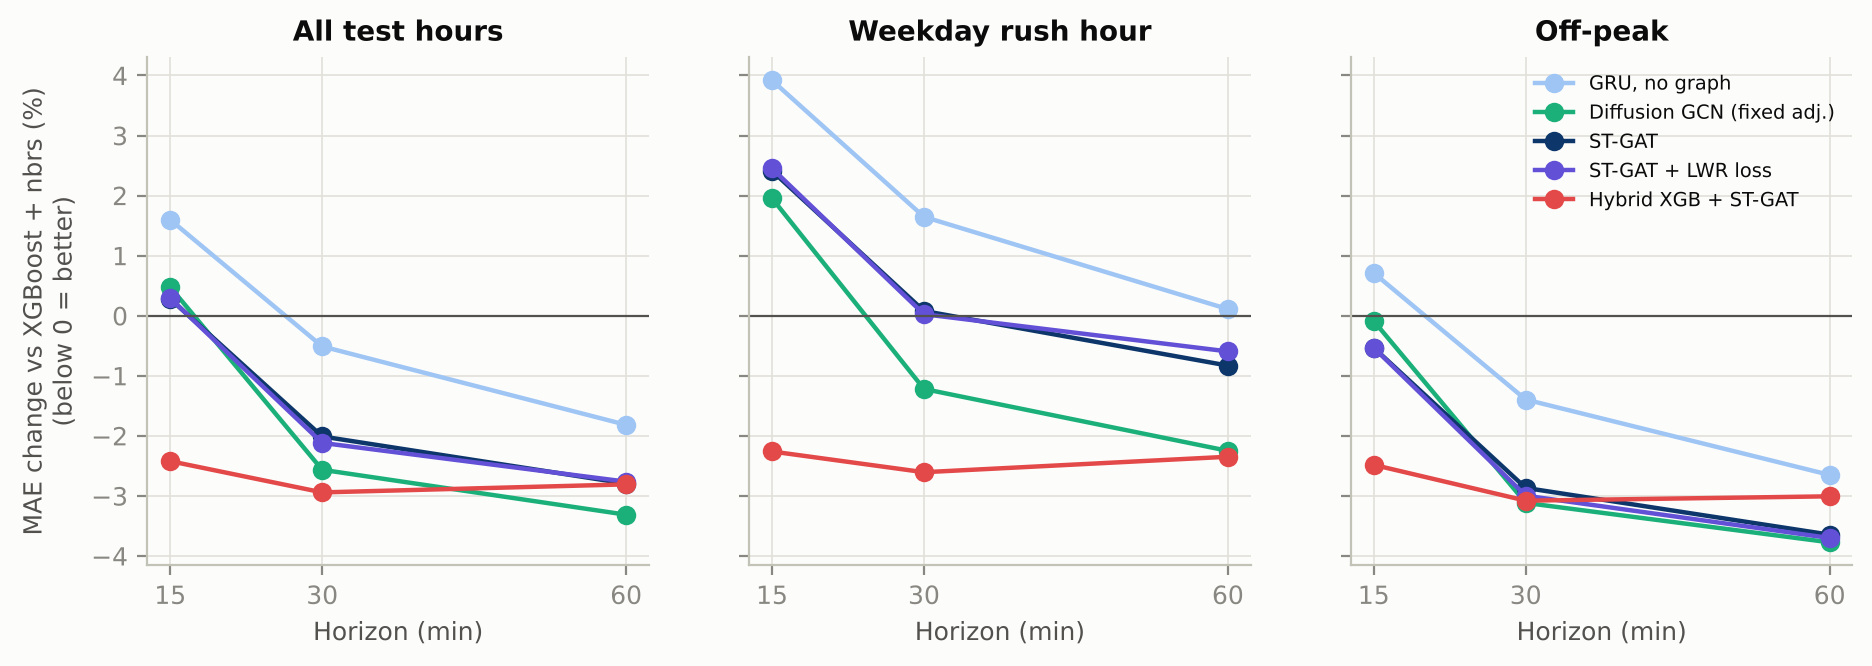

In [6]:
fig("fig_dl_mae_by_horizon", 860); fig("fig_dl_gain_vs_xgb", 900)

## 5. Is the difference real? Diebold–Mariano test vs XGBoost + neighbours

In [7]:
pd.read_csv(DL / "diebold_mariano.csv").round(4)

,model,vs,horizon,DM,p_value
0,DCRNN-lite,XGB-spatial,15min,2.620,0.009
1,DCRNN-lite,XGB-spatial,30min,-9.899,0.000
2,DCRNN-lite,XGB-spatial,60min,-8.439,0.000
3,GRU-nograph,XGB-spatial,15min,8.489,0.000
4,GRU-nograph,XGB-spatial,30min,-2.050,0.040
5,GRU-nograph,XGB-spatial,60min,-4.717,0.000
6,Hybrid-XGB-GAT,XGB-spatial,15min,-33.943,0.000
7,Hybrid-XGB-GAT,XGB-spatial,30min,-27.865,0.000
8,Hybrid-XGB-GAT,XGB-spatial,60min,-19.854,0.000
9,Hybrid-XGB-nograph,XGB-spatial,15min,-33.124,0.000


## 6. Ablations (12-epoch budget, compared with ST-GAT-short) and seeds

,15min,30min,60min,average,delta_15min,delta_60min
model,,,,,,
HA,4.193,4.193,4.194,4.193,1.194,0.115
Persistence,3.485,4.180,5.333,4.333,0.486,1.254
Ridge-local,3.229,3.924,4.960,4.038,0.230,0.882
XGB-local,2.991,3.437,3.851,3.426,-0.008,-0.227
XGB-spatial,2.867,3.323,3.783,3.324,-0.132,-0.296
RF-local,2.974,3.415,3.865,3.418,-0.025,-0.213
RF-spatial,2.872,3.309,3.810,3.331,-0.127,-0.268
DCRNN-lite,2.881,3.238,3.657,3.259,-0.118,-0.421
GRU-nograph,2.913,3.306,3.714,3.311,-0.086,-0.364


,horizon,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MAPE_mean,MAPE_std
0,15min,2.969,0.029,5.697,0.068,8.355,0.213
1,30min,3.407,0.036,6.755,0.076,10.122,0.256
2,60min,4.020,0.054,8.083,0.121,12.699,0.320
3,average,3.465,0.040,6.914,0.090,10.392,0.259


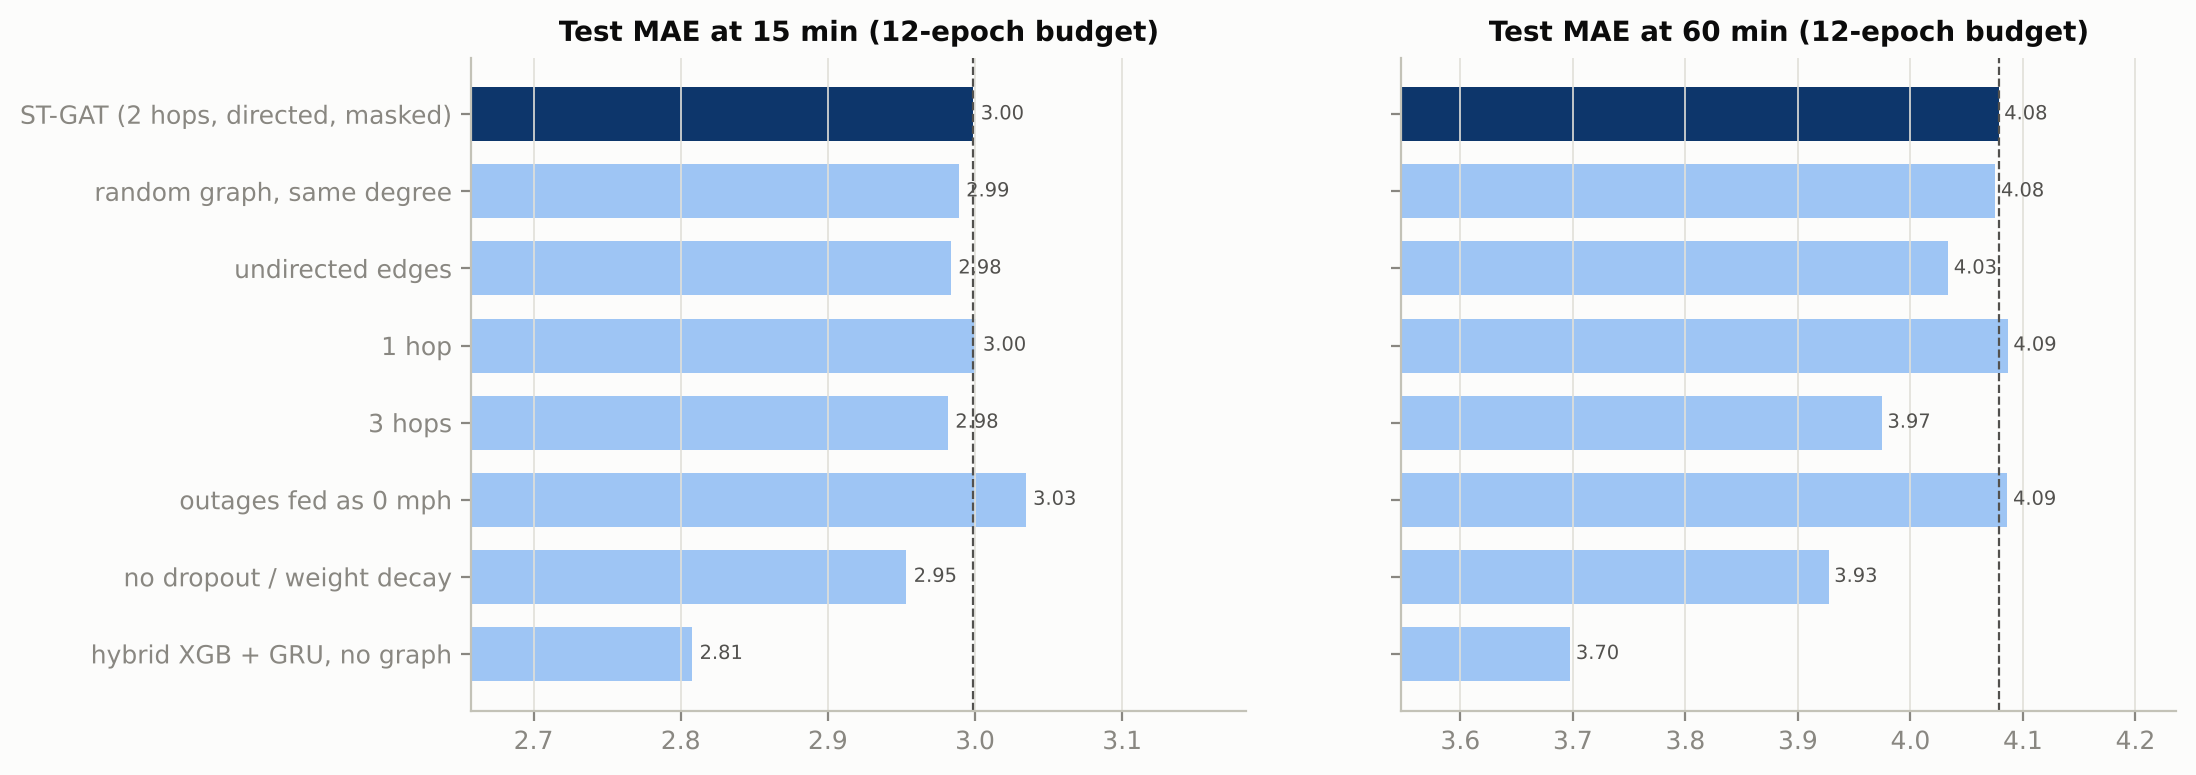

In [8]:
ab = pd.read_csv(DL / "ablations.csv").set_index("model")
display(ab[["15min", "30min", "60min", "average", "delta_15min", "delta_60min"]].round(3))
f = DL / "seeds_summary.csv"
if f.exists(): display(pd.read_csv(f).round(3))
fig("fig_dl_ablations", 900)

## 7. Rush hour, maps and attention

period,off-peak,peak
model,,
DCRNN-lite,3.182,5.538
GRU-nograph,3.219,5.672
HA,3.604,6.528
Hybrid-XGB-GAT,3.208,5.533
Persistence,4.713,7.786
RF-spatial,3.327,5.726
ST-GAT,3.187,5.619
ST-GAT-LWR,3.185,5.632
XGB-spatial,3.307,5.666


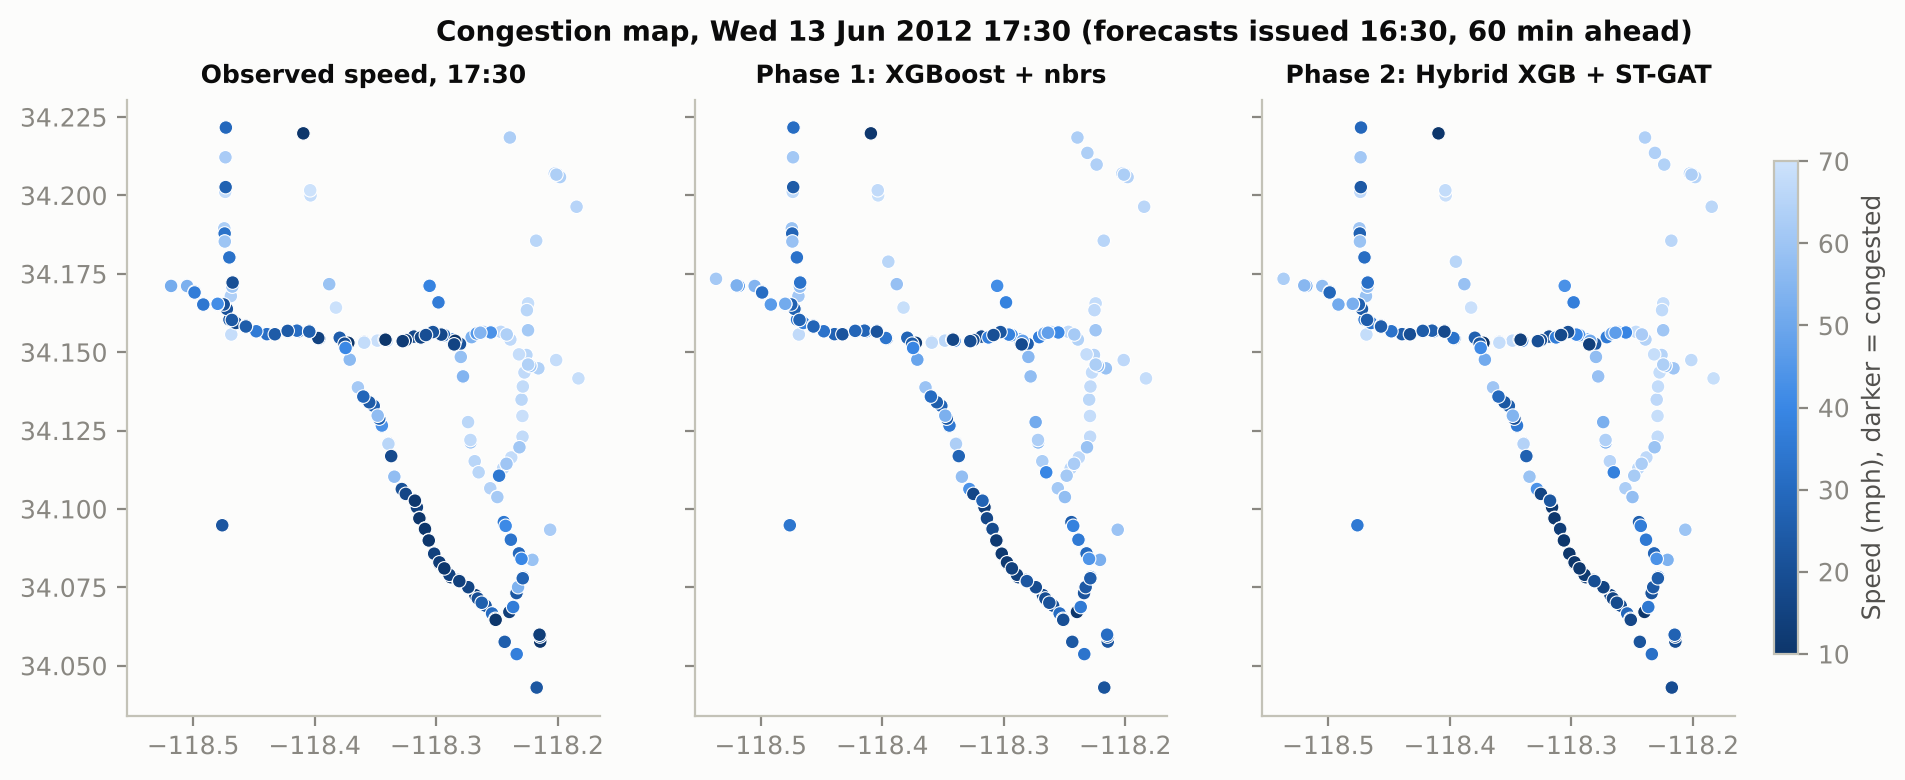

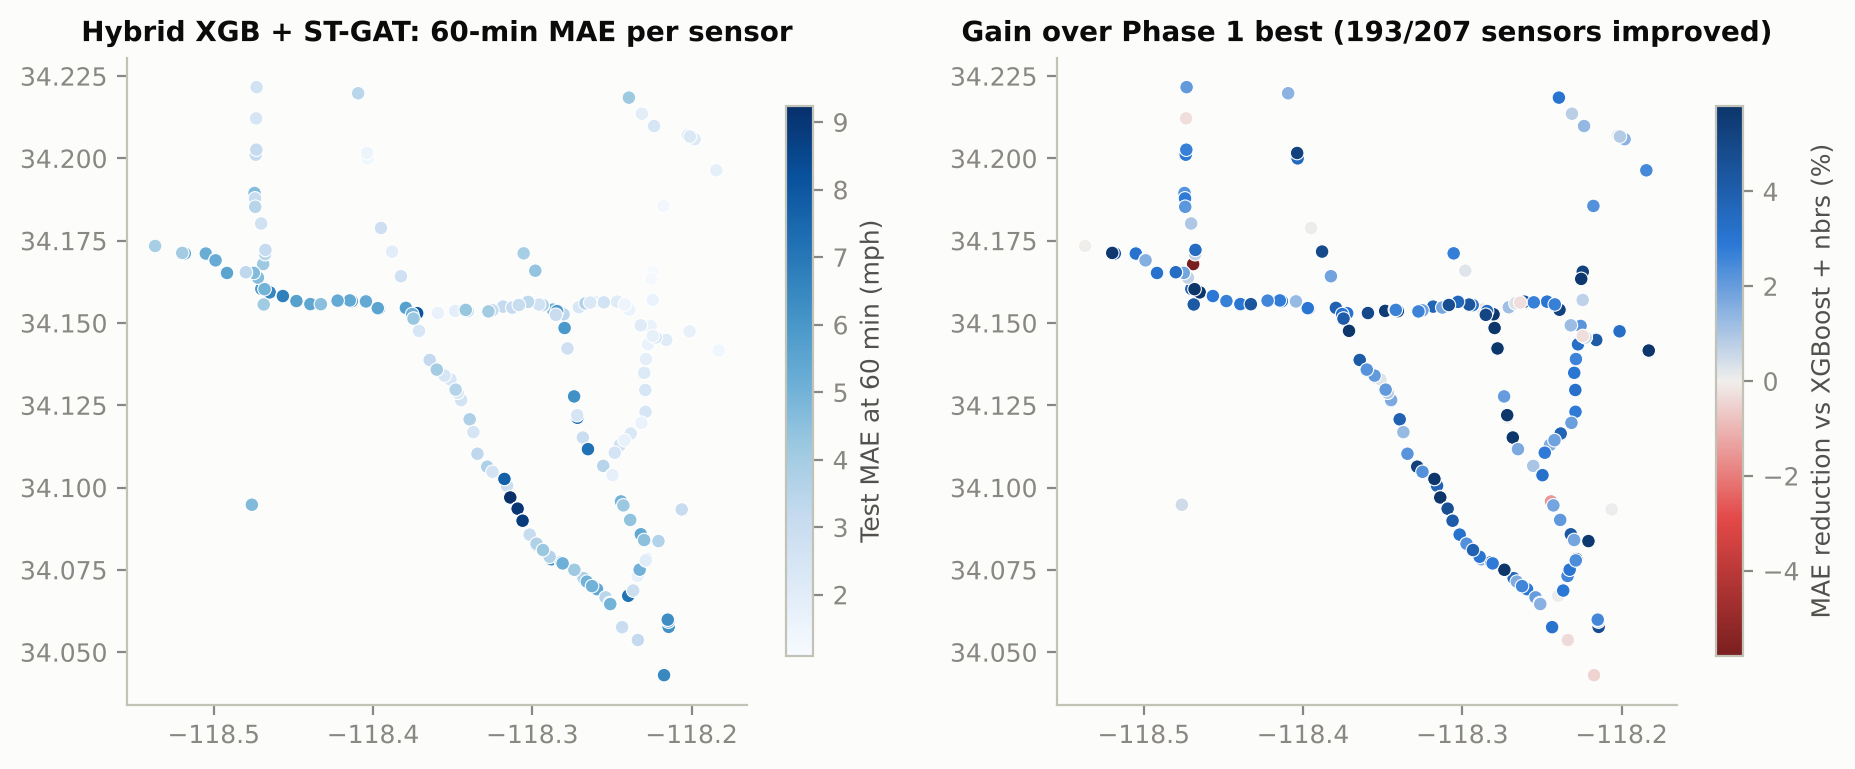

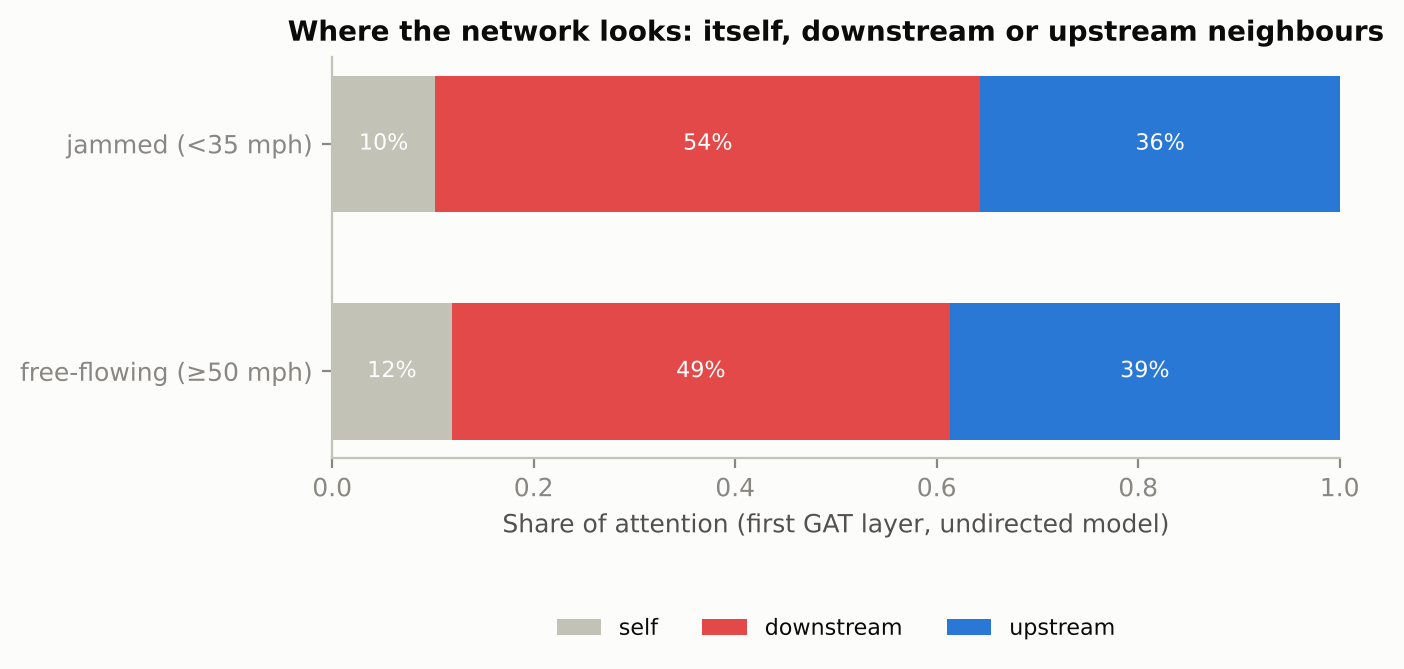

,model,relation,state,edge_type,attention_share
0,ST-GAT,rel0,jammed,self,0.210
1,ST-GAT,rel0,jammed,downstream,0.790
2,ST-GAT,rel0,jammed,upstream,0.000
3,ST-GAT,rel0,free,self,0.236
4,ST-GAT,rel0,free,downstream,0.764
5,ST-GAT,rel0,free,upstream,0.000
6,ST-GAT,rel1,jammed,self,0.193
7,ST-GAT,rel1,jammed,downstream,0.000
8,ST-GAT,rel1,jammed,upstream,0.807
9,ST-GAT,rel1,free,self,0.227


In [9]:
pk = pd.read_csv(DL / "metrics_peak_offpeak.csv")
display(pk[(pk.horizon == "60min") & pk.model.isin(main)].pivot(index="model", columns="period", values="MAE").round(3))
fig("fig_dl_congestion_map", 900); fig("fig_dl_sensor_gain_map", 900)
fig("fig_dl_attention", 650)
display(pd.read_csv(DL / "attention_analysis.csv").round(3).head(12))